In [ ]:
#Name: Swaraj Suresh Shinde
#PRN: 125B1D053
#Batch: A3
#Assignment 3c

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [9]:
!pip install seaborn

In [10]:
import seaborn as sns

In [11]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# Fetch Adult dataset
adult = fetch_ucirepo(id=2)

# Features and target
X = adult.data.features
y = adult.data.targets

# Combine them into one dataframe
df = pd.concat([X, y], axis=1)

df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [13]:
df.shape

(48842, 15)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


In [15]:
#check missing values
df.isnull().sum()

age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64

In [16]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [17]:
#Q1: central tendency of the age
age_mean = df['age'].mean()
age_median = df['age'].median()
age_mode = df['age'].mode()

print("Mean: ",age_mean)
print("Median: ",age_median)
print("Mode: ",age_mode)

#mean and median are close to 37-38

Mean:  38.64358543876172
Median:  37.0
Mode:  0    36
Name: age, dtype: int64


Text(0.5, 1.0, 'freq v/s age')

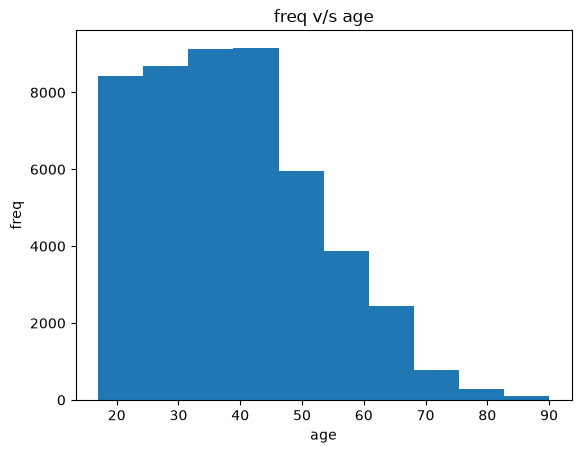

In [18]:
plt.hist(df['age'])
plt.xlabel('age')
plt.ylabel('freq')
plt.title('freq v/s age')

In [19]:
#Q2: is age distribution skew or symmetric 
#use .skew(), if skew = 0 then symm, skew>0 right skew else left skew
skewness = df['age'].skew()
print(skewness)

#thus, right skew

0.5575803166133181


In [20]:
kurtosis = df['age'].kurt()
print(kurtosis)

-0.18426874062387766


<Axes: ylabel='age'>

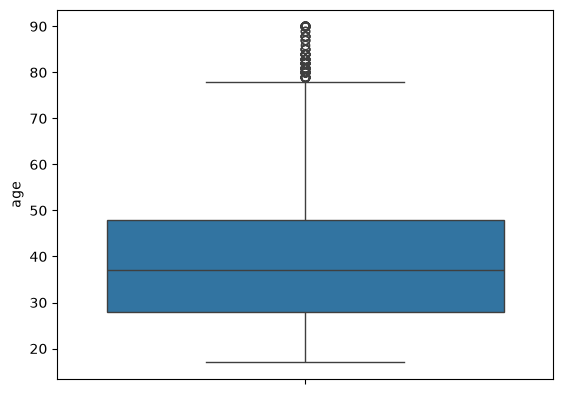

In [21]:
sns.boxplot(df['age'])


In [22]:
#Q3: to find outlier we will use iqr method
q1 = df['age'].quantile(0.25) #first 25% age
q3 = df['age'].quantile(0.75)

iqr = q3-q1

lower_bound = q1-1.5*iqr
upper_bound = q3 + 1.5*iqr

print(lower_bound)
print(upper_bound)

#any value outside this range is outlier


-2.0
78.0


In [23]:
print(df['age'].dtype)

int64


In [24]:
#for age min value is 19 and max is 90, so we will only take values above upperbound to find outlier
print((df['age']>78).sum())

#thus number of outliers are calculated

216


In [25]:
#Q4:variation of age across diffrent groups and regions
df.groupby('sex')['age'].mean()

sex
Female    36.927989
Male      39.494395
Name: age, dtype: float64

In [26]:
df.groupby('sex')['age'].median()

sex
Female    35.0
Male      38.0
Name: age, dtype: float64

In [27]:
df.groupby('sex')['age'].min()

sex
Female    17
Male      17
Name: age, dtype: int64

In [28]:
df.groupby('sex')['age'].max()

sex
Female    90
Male      90
Name: age, dtype: int64

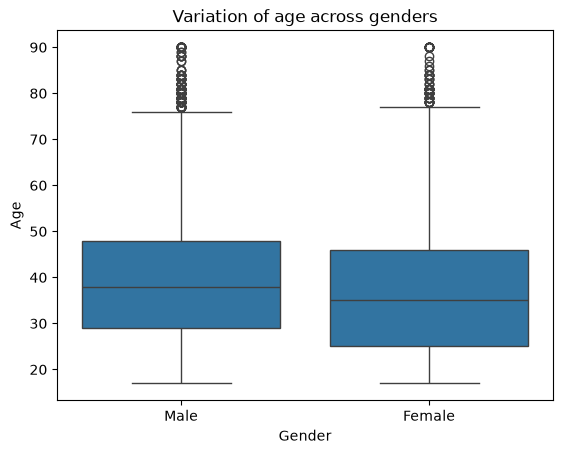

In [29]:
sns.boxplot(data=df, x='sex', y='age')
plt.xlabel('Gender')
plt.ylabel('Age')
plt.title('Variation of age across genders')
plt.show()

In [30]:
# variation of age wrt education
df.groupby('education')['age'].mean()

education
10th            37.902808
11th            32.141832
12th            32.235921
1st-4th         46.639676
5th-6th         43.585462
7th-8th         49.525654
9th             40.902116
Assoc-acdm      37.777014
Assoc-voc       38.651140
Bachelors       38.896324
Doctorate       47.530303
HS-grad         39.073809
Masters         44.006775
Preschool       42.204819
Prof-school     45.152278
Some-college    35.677055
Name: age, dtype: float64

In [31]:
df.groupby('education')['age'].median()

education
10th            35.0
11th            28.0
12th            28.0
1st-4th         46.0
5th-6th         43.0
7th-8th         51.0
9th             39.0
Assoc-acdm      37.0
Assoc-voc       37.0
Bachelors       37.0
Doctorate       47.0
HS-grad         37.0
Masters         44.0
Preschool       41.0
Prof-school     43.0
Some-college    34.0
Name: age, dtype: float64

In [32]:
df.groupby('education')['age'].max()

education
10th            90
11th            90
12th            81
1st-4th         90
5th-6th         84
7th-8th         90
9th             90
Assoc-acdm      90
Assoc-voc       84
Bachelors       90
Doctorate       80
HS-grad         90
Masters         90
Preschool       77
Prof-school     90
Some-college    90
Name: age, dtype: int64

In [33]:
df.groupby('education')['age'].min()

education
10th            17
11th            17
12th            17
1st-4th         19
5th-6th         17
7th-8th         17
9th             17
Assoc-acdm      19
Assoc-voc       19
Bachelors       19
Doctorate       24
HS-grad         17
Masters         18
Preschool       19
Prof-school     25
Some-college    17
Name: age, dtype: int64

In [34]:
df.groupby('native-country')['age'].mean()

native-country
?                             38.725557
Cambodia                      36.892857
Canada                        44.049451
China                         41.852459
Columbia                      39.458824
Cuba                          46.355072
Dominican-Republic            37.970874
Ecuador                       37.666667
El-Salvador                   33.380645
England                       40.527559
France                        40.315789
Germany                       38.601942
Greece                        45.836735
Guatemala                     32.090909
Haiti                         38.600000
Holand-Netherlands            32.000000
Honduras                      35.050000
Hong                          34.233333
Hungary                       50.368421
India                         38.364238
Iran                          38.372881
Ireland                       38.486486
Italy                         45.419048
Jamaica                       37.141509
Japan                    

In [35]:
df.groupby('native-country')['age'].mean()

native-country
?                             38.725557
Cambodia                      36.892857
Canada                        44.049451
China                         41.852459
Columbia                      39.458824
Cuba                          46.355072
Dominican-Republic            37.970874
Ecuador                       37.666667
El-Salvador                   33.380645
England                       40.527559
France                        40.315789
Germany                       38.601942
Greece                        45.836735
Guatemala                     32.090909
Haiti                         38.600000
Holand-Netherlands            32.000000
Honduras                      35.050000
Hong                          34.233333
Hungary                       50.368421
India                         38.364238
Iran                          38.372881
Ireland                       38.486486
Italy                         45.419048
Jamaica                       37.141509
Japan                    

In [36]:
df.groupby('native-country')['age'].min()

native-country
?                             17
Cambodia                      18
Canada                        17
China                         21
Columbia                      17
Cuba                          18
Dominican-Republic            18
Ecuador                       21
El-Salvador                   17
England                       17
France                        20
Germany                       18
Greece                        22
Guatemala                     17
Haiti                         17
Holand-Netherlands            32
Honduras                      18
Hong                          19
Hungary                       24
India                         17
Iran                          22
Ireland                       23
Italy                         18
Jamaica                       18
Japan                         19
Laos                          19
Mexico                        17
Nicaragua                     19
Outlying-US(Guam-USVI-etc)    20
Peru                        

In [37]:
df.groupby('native-country')['age'].max()

native-country
?                             90
Cambodia                      65
Canada                        80
China                         76
Columbia                      75
Cuba                          82
Dominican-Republic            78
Ecuador                       90
El-Salvador                   79
England                       90
France                        69
Germany                       74
Greece                        81
Guatemala                     66
Haiti                         63
Holand-Netherlands            32
Honduras                      61
Hong                          60
Hungary                       81
India                         64
Iran                          63
Ireland                       68
Italy                         77
Jamaica                       66
Japan                         72
Laos                          56
Mexico                        81
Nicaragua                     78
Outlying-US(Guam-USVI-etc)    63
Peru                        

In [38]:
#Additional queries
#Q1: calculate number of males and females
#male are almost double to females

df['sex'].value_counts()

sex
Male      32650
Female    16192
Name: count, dtype: int64

In [39]:
#Q2: calculate number of people in each degree
#here most people have hs grad
df['education'].value_counts()

education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
9th               756
12th              657
Doctorate         594
5th-6th           509
1st-4th           247
Preschool          83
Name: count, dtype: int64

In [40]:
#Q3: calculate no. of people in each country
df['native-country'].value_counts()

#data is majorily usa based

native-country
United-States                 43832
Mexico                          951
?                               583
Philippines                     295
Germany                         206
Puerto-Rico                     184
Canada                          182
El-Salvador                     155
India                           151
Cuba                            138
England                         127
China                           122
South                           115
Jamaica                         106
Italy                           105
Dominican-Republic              103
Japan                            92
Guatemala                        88
Poland                           87
Vietnam                          86
Columbia                         85
Haiti                            75
Portugal                         67
Taiwan                           65
Iran                             59
Greece                           49
Nicaragua                        49
Peru         

In [41]:
#Q4: which working sector has highest no of people
df['workclass'].value_counts()


workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
?                    1836
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

In [42]:
#Q5: avg working hours
print(df['hours-per-week'].mean())

40.422382375824085


In [43]:
#Q6; most people work how many hours
print(df['hours-per-week'].median())

40.0


In [44]:
print(df['hours-per-week'].max())
print(df['hours-per-week'].min())

99
1


In [45]:
#Q7: variation of working hours wrt gender
df.groupby('sex')['hours-per-week'].mean()

sex
Female    36.400692
Male      42.416845
Name: hours-per-week, dtype: float64

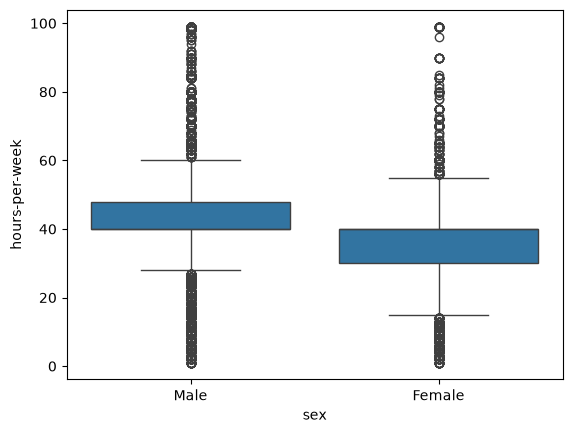

In [46]:
sns.boxplot(data=df,x='sex',y='hours-per-week')
plt.show()

In [47]:
#Q8:variation of age wrt income
df.groupby('income')['age'].mean()

income
<=50K     36.783738
<=50K.    37.048010
>50K      44.249841
>50K.     44.326833
Name: age, dtype: float64

In [48]:
df.groupby('income')['age'].median()

income
<=50K     34.0
<=50K.    34.0
>50K      44.0
>50K.     43.0
Name: age, dtype: float64

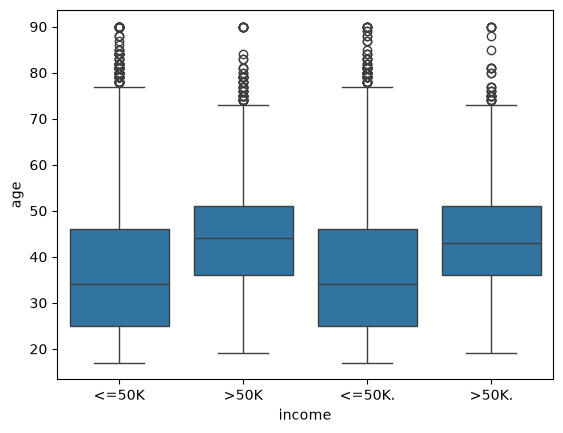

In [49]:
sns.boxplot(data=df,x='income',y='age')
plt.show()